# HERDSMAN: quickstart, paper reproduction and PyPI release in one notebook

This notebook replaces `03_quickstart.ipynb`, `02_experiments.ipynb` and `01_case_study_northfell.ipynb` and runs from top to bottom with nothing but the release archive `herdsman-0_1_0-release.zip` beside it. It works in five parts:

1. **Set-up.** Installs dependencies, unpacks the release and puts the package and the experiment modules on the path.
2. **Quickstart** (formerly notebook 03): one analysis from first test to signed certificate.
3. **Simulation experiments** (formerly notebook 02): determinism check, then every simulation table and figure in *Refereeing the Robot Analyst* from the stored results.
4. **Case study** (formerly notebook 01). The release ships audit bundles rather than live study directories, so the six Northfell studies are first rebuilt by deterministic replay of their ledgers, checked e-value for e-value against the published bundles, and re-scored against the oracle before the original analysis runs.
5. **Package and publish.** Stages the package, runs the test suite, builds and checks the sdist and wheel, smoke-tests the wheel in a clean virtual environment, uploads to PyPI (or TestPyPI) and confirms the published package installs and works.

The upload is the only step with an irreversible effect: a version number, once uploaded, can never be reused on PyPI, even after deletion. It runs only if every earlier check passed and an API token is available. Set the configuration below before running.

In [1]:
# ---------------------------------------------------------------- configuration
from pathlib import Path
import os

RELEASE_ZIP = Path(r"C:\Users\john.christiansen\Desktop\herdsman-0.1.0-release.zip")   # the release archive
WORK = Path(r"C:\Users\john.christiansen\Desktop\Herdsman")                         # unpacked and built here; safe to delete
# Use raw strings (r"...") for Windows paths. Keep WORK outside OneDrive: syncing the build folders is slow.

INSTALL_DEPENDENCIES = True   # pip-install what the notebook needs into this kernel's environment
FULL_RERUN = False            # True: re-run every simulation script from scratch (tens of minutes) and compare with the stored results
RERUN_WORKERS = 2

PUBLISH = True                # build, check and upload the package in Part 5
REPOSITORY = "pypi"           # "pypi" for the real index, "testpypi" for a rehearsal on test.pypi.org
TOKEN_ENV = {"pypi": "PYPI_API_TOKEN", "testpypi": "TEST_PYPI_API_TOKEN"}[REPOSITORY]
# The token is read from the environment variable above; if it is missing you will be prompted for it.
# Create one at https://pypi.org/manage/account/token/ (or test.pypi.org). Never paste it into this notebook.

## Part 1. Set-up

In [2]:
import sys, subprocess, zipfile, shutil, json

def sh(*args, check=True, quiet=False, env=None, cwd=None):
    # run a command, echo its output, raise if it fails
    proc = subprocess.run([str(a) for a in args], capture_output=True, text=True, env=env, cwd=cwd)
    out = (proc.stdout + proc.stderr).strip()
    if out and not quiet:
        print(out[-6000:])
    if check and proc.returncode != 0:
        if quiet:
            print(out[-6000:])
        raise RuntimeError(f"command failed ({proc.returncode}): {' '.join(map(str, args[:4]))} ...")
    return proc

REQUIREMENTS = ["numpy>=1.24", "pandas>=2.0", "scipy", "matplotlib", "cryptography>=41", "mcp>=1.2",
                "pytest>=8", "build", "twine>=5", "packaging", "requests"]
if INSTALL_DEPENDENCIES:
    sh(sys.executable, "-m", "pip", "install", "--quiet", "--disable-pip-version-check", *REQUIREMENTS, quiet=True)
    print("dependencies installed")
print(sys.version)

dependencies installed
3.11.5 (tags/v3.11.5:cce6ba9, Aug 24 2023, 14:38:34) [MSC v.1936 64 bit (AMD64)]


In [3]:
RELEASE_ZIP = RELEASE_ZIP.resolve()
WORK = WORK.resolve()
RELEASE = WORK / "release"
if not RELEASE_ZIP.exists():
    raise FileNotFoundError(f"release archive not found at {RELEASE_ZIP}; set RELEASE_ZIP in the configuration cell")
if RELEASE.exists():
    shutil.rmtree(RELEASE)
RELEASE.mkdir(parents=True)
with zipfile.ZipFile(RELEASE_ZIP) as zf:
    zf.extractall(RELEASE)

REPO = RELEASE / "herdsman"              # the repository: src/, tests/, experiments/, results/, ...
CASE_RELEASE = RELEASE / "casestudy"     # audit bundles, agents' deliverables and replies for the six runs
CASE_ROOT = WORK / "casestudy"           # where the six studies are rebuilt in Part 4
RES = REPO / "results"

# the package itself is imported straight from source; Part 5 tests the built wheel separately
for p in (REPO / "experiments", REPO / "src"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

if not (REPO / "src" / "herdsman" / "_filelock.py").exists():
    raise RuntimeError("this release predates the Windows fix (it imports fcntl, which Windows lacks); use the patched herdsman-0.1.0-release.zip")

import herdsman
print("herdsman", herdsman.__version__, "from", Path(herdsman.__file__).parent)
print("runs in release:", sorted(p.name for p in CASE_RELEASE.iterdir() if p.is_dir()))

herdsman 0.1.0 from C:\Users\john.christiansen\Desktop\Herdsman\release\herdsman\src\herdsman
runs in release: ['H1', 'N1', 'N2', 'P1', 'P2', 'S1']


In [4]:
import matplotlib as mpl
NAVY, TEAL, AMBER, SLATE, SAND = "#0B2545", "#1F8A8A", "#E09F3E", "#5B6B7F", "#D9D4C7"
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.edgecolor": SLATE, "axes.labelcolor": NAVY, "xtick.color": SLATE, "ytick.color": SLATE,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#ECE8DF",
    "grid.linewidth": 0.8, "axes.prop_cycle": mpl.cycler(color=[TEAL, AMBER, NAVY, SLATE, "#8FB8B8", "#C9A26B"]),
    "legend.frameon": False,
})

import math, tempfile, io, contextlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import herdsman as bu
from herdsman import Referee, RefereeError, verify_document, verify_bundle
from herdsman.canonical import FixedClock
from herdsman.claims import Claim
pd.set_option("display.width", 170); pd.set_option("display.max_colwidth", 90)
read = lambda name: pd.read_csv(RES / name, keep_default_na=False, na_values=[""])
print("herdsman", bu.__version__, "| demo mode:", bu.demo_mode())

herdsman 0.1.0 | demo mode: True


## Part 2. Quickstart: from first test to signed certificate

One analysis walks through the referee: a study is created and sealed, an analyst explores and commits claims, the referee opens sealed folds one episode at a time, and the claims that survive receive signed certificates that anyone can verify. The data are synthetic with a known answer, so the referee's decisions are checked against the truth at the end. `DEMO_MODE` is on, so no language model is called.

### 2.1 An experiment with a known answer

An online retailer tests a new checkout (B) against the current one (A) on 30,000 customers. By construction, B lifts conversion by six points for **new** customers and does nothing for anyone else, and it has no effect on basket value.

In [5]:
rng = np.random.default_rng(2026)
n = 30_000
data = pd.DataFrame({
    "variant": rng.choice(["A", "B"], n),
    "tenure": rng.choice(["new", "established", "loyal"], n, p=[0.3, 0.5, 0.2]),
    "device": rng.choice(["mobile", "desktop"], n),
    "region": rng.choice(["north", "south", "east", "west"], n),
    "plan": rng.choice(["basic", "plus", "pro"], n, p=[0.6, 0.3, 0.1]),
})
lift = 0.06 * ((data.variant == "B") & (data.tenure == "new"))
data["converted"] = rng.binomial(1, 0.20 + lift)
data["basket_value"] = np.clip(rng.gamma(4, 20, n) + 25 * (data.plan == "pro"), 0, 500).round(2)
data.groupby(["tenure", "variant"]).converted.mean().unstack().round(3)

variant,A,B
tenure,,
established,0.196,0.193
loyal,0.194,0.205
new,0.196,0.255


### 2.2 The data owner creates a study

`Referee.create` shuffles the rows with a seeded generator and keeps 40% open for exploration. The other 60% is split into three folds, each encrypted with a key written to a separate keys directory. The SHA-256 of every fold and of the seed is published in `study.json` before anyone looks at the data, so the referee cannot quietly swap a fold or re-draw the randomness later. The error budget is a false discovery rate of 10% spread evenly over ten claim slots.

In [6]:
qs_work = Path(tempfile.mkdtemp(prefix="herdsman-quickstart-"))
referee = Referee.create(
    qs_work / "study", qs_work / "keys", data,
    outcomes=["converted", "basket_value"], bounds={"basket_value": (0, 500)},
    alpha=0.10, horizon=10, n_folds=3, exploration_fraction=0.4, seed=11,
    title="Checkout B experiment", question="Did checkout B work, and for whom?",
    clock=FixedClock("2026-11-07T09:00:00Z"),
)
params = referee.params
print("study", params["study_id"], "| referee key", params["referee_key_fingerprint"])
print("fold commitments:", [f["sha256"][:12] for f in params["vault"]["commitments"]["folds"]])
print("seed commitment:", params["seed_commitment"][:24], "...")
referee.budget()

study cf71bfbd4b71 | referee key fde849bf61c04d7f
fold commitments: ['9de76a97d9da', '08de95c20a27', 'f0861be84035']
seed commitment: b7f89d9a2ffc5a62c8926106 ...


{'alpha': 0.1,
 'policy': 'uniform over 10 claim slots',
 'claim_slots': 10,
 'claims_committed': 0,
 'slots_left': 10,
 'certified': 0,
 'next_claim_level': 0.010000000000000002,
 'next_claim_threshold_e': 99.99999999999999,
 'episode': 1,
 'folds_used': 0,
 'folds_remaining': 3,
 'accepting_claims': True,
 'mode': 'rolling',
 'batch_procedure': None}

### 2.3 The analyst's view

The analyst (a person or an agent) opens the study **without** the keys. It can read the exploration data, run logged tests and commit claims. It cannot open a sealed fold.

In [7]:
analyst = Referee(qs_work / "study", clock=FixedClock("2026-11-07T10:00:00Z"))
brief = analyst.brief()
print(brief["title"], "|", brief["exploration_rows"], "exploration rows |", "outcomes:", brief["outcomes"])
for rule in brief["rules"]:
    print("-", rule)

Checkout B experiment | 12000 exploration rows | outcomes: ['converted', 'basket_value']
- Explore the exploration data as much as you like; tests run through the referee are logged.
- Commit a claim when you want it certified. Its required evidence is fixed at commit.
- At the end of the episode the referee opens one sealed fold you have never seen and updates every open claim.
- A claim is certified when its accumulated e-value reaches 1/alpha_t. Open claims keep accumulating on later folds.
- Spent folds are released to you afterwards; new claims are only ever tested on folds you have not seen.


### 2.4 Explore: a small forking-paths search

The analyst tests the effect of B on both outcomes, overall and in every single-attribute subgroup, plus every tenure-by-device cell: 38 tests. Each one is written to the ledger.

In [8]:
groups = [("", "everyone")] + [(f"{c} == '{v}'", f"{c}={v}") for c in ["tenure", "device", "region", "plan"] for v in sorted(data[c].unique())]
groups += [(f"tenure == '{t}' and device == '{d}'", f"{t}+{d}") for t in ["new", "established", "loyal"] for d in ["mobile", "desktop"]]
rows = []
for outcome in ["converted", "basket_value"]:
    for population, label in groups:
        spec = {"outcome": outcome, "population": population, "focal": "variant == 'B'", "reference": "variant == 'A'"}
        r = analyst.explore_test(spec)
        rows.append({"outcome": outcome, "subgroup": label, "estimate": r["estimate"], "z": r["z"], "p": r["p_two_sided"], "population": population})
search = pd.DataFrame(rows).sort_values("p")
print(len(search), "tests;", (search.p < 0.05).sum(), "significant at 5%")
search.head(8).round(4)

38 tests; 6 significant at 5%


,outcome,subgroup,estimate,z,p,population
3,converted,tenure=new,0.0533,3.8214,0.0001,tenure == 'new'
13,converted,new+mobile,0.0674,3.4971,0.0005,tenure == 'new' and device == 'mobile'
12,converted,plan=pro,0.0614,2.6459,0.0081,plan == 'pro'
7,converted,region=north,0.0316,2.1899,0.0285,region == 'north'
5,converted,device=mobile,0.0214,2.0872,0.0369,device == 'mobile'
14,converted,new+desktop,0.0402,1.9902,0.0466,tenure == 'new' and device == 'desktop'
36,basket_value,loyal+mobile,4.6673,1.9136,0.0557,tenure == 'loyal' and device == 'mobile'
37,basket_value,loyal+desktop,-4.5663,-1.8731,0.0611,tenure == 'loyal' and device == 'desktop'


In [9]:
d = analyst.disclosure()
print(f"{d['tests']} tests in {d['families']} families; {d['significant_at_alpha']} significant at 5% "
      f"against {d['expected_significant_if_all_null']:.1f} expected if nothing were real; {d['bh_survivors']} survive BH at 10%.")
pd.DataFrame(d["family_table"])[["family", "tests", "significant_at_alpha", "min_p", "bonferroni_min_p"]]

38 tests in 2 families; 6 significant at 5% against 1.9 expected if nothing were real; 2 survive BH at 10%.


,family,tests,significant_at_alpha,min_p,bonferroni_min_p
0,converted ~ variant,19,6,0.000133,0.002521
1,basket_value ~ variant,19,0,0.055669,1.000000


### 2.5 Commit claims

The analyst commits the five most significant results, in the direction it observed. The level each claim needs is fixed now, by e-LOND: with ten slots and α = 10%, the first claim must reach an e-value of 100. Each certification lowers the bar for claims committed afterwards. The analyst's handle cannot close an episode.

In [10]:
for _, row in search.head(5).iterrows():
    direction = "increase" if row.estimate > 0 else "decrease"
    analyst.commit_claim({
        "statement": f"Checkout B {'raises' if direction == 'increase' else 'lowers'} {row.outcome} ({row.subgroup})",
        "outcome": row.outcome, "population": row.population,
        "focal": "variant == 'B'", "reference": "variant == 'A'", "direction": direction,
    })
pd.DataFrame(analyst.claims())[["id", "statement", "alpha_t", "threshold_e", "status"]]

,id,statement,alpha_t,threshold_e,status
0,C001,Checkout B raises converted (tenure=new),0.01,100.0,open
1,C002,Checkout B raises converted (new+mobile),0.01,100.0,open
2,C003,Checkout B raises converted (plan=pro),0.01,100.0,open
3,C004,Checkout B raises converted (region=north),0.01,100.0,open
4,C005,Checkout B raises converted (device=mobile),0.01,100.0,open


In [11]:
try:
    analyst.close_episode()
except RefereeError as err:
    print("Analyst handle refused:", err)

Analyst handle refused: this handle has no referee keys; only the referee can open sealed folds


### 2.6 The referee closes episode 1

One sealed fold is opened. Every open claim gets that fold's e-value, which multiplies into its running evidence. The fold is then released into the exploration pool: it is spent, because no claim committed from now on will be tested on it.

In [12]:
episode1 = referee.close_episode()
print("fold", episode1["fold"], "opened; certified now:", [c["id"] for c in episode1["certified"]])
pd.DataFrame(referee.claims())[["id", "statement", "status", "log10_e", "threshold_e"]].round(2)

fold 1 opened; certified now: ['C001']


,id,statement,status,log10_e,threshold_e
0,C001,Checkout B raises converted (tenure=new),certified,3.29,100.0
1,C002,Checkout B raises converted (new+mobile),open,1.38,100.0
2,C003,Checkout B raises converted (plan=pro),open,1.54,100.0
3,C004,Checkout B raises converted (region=north),open,-0.18,100.0
4,C005,Checkout B raises converted (device=mobile),open,0.43,100.0


### 2.7 Episode 2: more data for the analyst, fresh data for the referee

The analyst now explores 40% + 20% of the rows and commits one more, refined claim, which will only ever be tested on folds 2 and 3. Earlier claims that are still open keep accumulating evidence.

In [13]:
print("exploration rows now:", len(analyst.exploration_data()))
for population, words in [("tenure == 'new' and device == 'mobile'", "new mobile customers"),
                          ("tenure == 'new' and plan == 'basic'", "new customers on the basic plan")]:
    try:
        analyst.commit_claim({"statement": f"Checkout B raises conversion for {words}", "outcome": "converted",
                              "population": population, "focal": "variant == 'B'", "reference": "variant == 'A'"})
        print("committed:", words)
        break
    except RefereeError as err:
        print("skipped:", err)
final = referee.close_study()
qs_claims = pd.DataFrame(referee.claims())
qs_claims[["id", "statement", "episode", "status", "log10_e", "threshold_e", "certified_fold"]].round(2)

exploration rows now: 18000
skipped: this claim duplicates C002
committed: new customers on the basic plan


,id,statement,episode,status,log10_e,threshold_e,certified_fold
0,C001,Checkout B raises converted (tenure=new),1,certified,3.29,100.0,1.0
1,C002,Checkout B raises converted (new+mobile),1,certified,3.59,100.0,2.0
2,C003,Checkout B raises converted (plan=pro),1,certified,2.50,100.0,2.0
3,C004,Checkout B raises converted (region=north),1,expired,-0.35,100.0,NaN
4,C005,Checkout B raises converted (device=mobile),1,expired,0.64,100.0,NaN
5,C006,Checkout B raises conversion for new customers on the basic plan,2,certified,1.70,50.0,3.0


### 2.8 Checking against the truth

B helps new customers only. A claim is about the *average* effect in its population, so "B raises conversion among mobile customers" is true, if diluted: about 30% of mobile customers are new, so the average lift there is roughly 0.3 × 6 = 1.8 points. A claim is false if it concerns basket value, says B *lowers* conversion, or describes a population with no new customers. Certificates speak to the claim as written; they do not say which customers drive an effect.

In [14]:
def true_lift(member):
    # true average effect of B in the claim's population, from the generator rather than the data
    if member["outcome"] != "converted":
        return 0.0
    population = data if not member["population"] else data.query(member["population"])
    return 0.06 * (population.tenure == "new").mean()

def truly_true(row):
    member = row["members"][0]
    lift = true_lift(member)
    return lift > 0 if member["direction"] == "increase" else lift < 0

qs_claims["true_lift"] = qs_claims["members"].apply(lambda m: round(true_lift(m[0]), 4))
qs_claims["true"] = qs_claims.apply(truly_true, axis=1)
print(qs_claims[["id", "statement", "true_lift", "status"]].to_string(index=False))
print(pd.crosstab(qs_claims["true"], qs_claims["status"]))

  id                                                        statement  true_lift    status
C001                         Checkout B raises converted (tenure=new)     0.0600 certified
C002                         Checkout B raises converted (new+mobile)     0.0600 certified
C003                           Checkout B raises converted (plan=pro)     0.0179 certified
C004                       Checkout B raises converted (region=north)     0.0181   expired
C005                      Checkout B raises converted (device=mobile)     0.0183   expired
C006 Checkout B raises conversion for new customers on the basic plan     0.0600 certified
status  certified  expired
true                      
True            4        2


### 2.9 Evidence paths

Each line is a claim's accumulated evidence (log10 of the e-value) as sealed folds are opened; the dashed line is the evidence it needed.

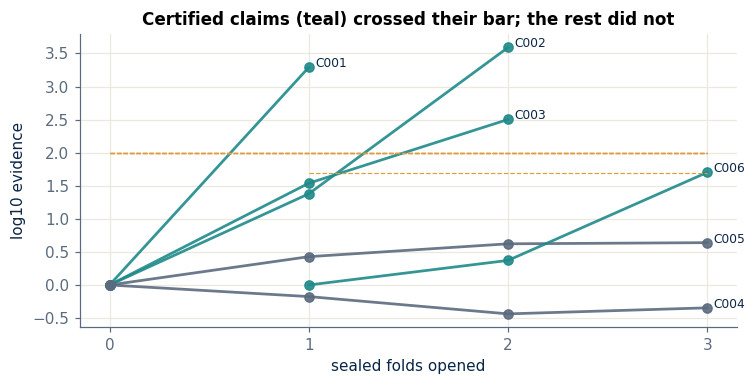

In [15]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for _, c in qs_claims.iterrows():
    folds = [c["episode"] - 1] + [s["fold"] for s in c["trajectory"]]
    path = [0.0] + [s["log_e_cumulative"] / math.log(10) for s in c["trajectory"]]
    ax.plot(folds, path, marker="o", lw=1.8, color=TEAL if c["status"] == "certified" else SLATE, alpha=0.9)
    ax.hlines(math.log10(c["threshold_e"]), folds[0], 3, colors=AMBER, linestyles="dashed", lw=0.8)
    ax.annotate(c["id"], (folds[-1], path[-1]), textcoords="offset points", xytext=(4, 0), fontsize=8, color=NAVY)
ax.set_xlabel("sealed folds opened"); ax.set_ylabel("log10 evidence"); ax.set_xticks([0, 1, 2, 3])
ax.set_title("Certified claims (teal) crossed their bar; the rest did not")
plt.tight_layout(); plt.show()

### 2.10 Certificates and audit

A certificate is a signed JSON document recording the claim, when and where in the ledger it was committed, the evidence it needed and accumulated, how many exploratory tests came before it, and the guarantee. Anyone with the referee's public key can verify it, and anyone can recompute the ledger's hash chain. Tampering with a copy of the ledger breaks the chain.

In [16]:
certified_ids = qs_claims.loc[qs_claims.status == "certified", "id"].tolist()
cert = referee.certificate(certified_ids[0])
print(json.dumps({k: cert[k] for k in ["claim_id", "statement", "commit", "disclosure", "guarantee"]}, indent=2)[:1800])
print("signature:", verify_document(cert, referee.params["referee_public_key"]))
print("whole study:", {k: v for k, v in referee.verify().items() if k in ("ok", "checkpoint_ok")})

{
  "claim_id": "C001",
  "statement": "Checkout B raises converted (tenure=new)",
  "commit": {
    "t": 1,
    "episode": 1,
    "actor": "analyst",
    "committed_at": "2026-11-07T10:00:38.000000Z",
    "ledger_seq": 40,
    "ledger_hash": "63395cab54747c0feaa8f09b7968a96ed3b75e8e09057cec3012ee43f3e9a75b",
    "alpha_t": 0.010000000000000002,
    "gamma_t": 0.1,
    "certified_before": 0,
    "threshold_e": 99.99999999999999
  },
  "disclosure": {
    "exploratory_tests_logged_before_commit": 38,
    "same_family_tests_before_commit": 19,
    "claims_committed_before": 0,
    "family": "converted ~ variant"
  },
  "guarantee": "Certified by online e-LOND at overall level alpha=0.1: across every claim committed in this study, the expected proportion of certified claims that are false is at most alpha, whatever the analyst did before committing them, provided the sealed folds are independent random samples from the study population. The certificate speaks to the statistical claim as s

In [17]:
# Tamper with a copy: make an early claim look as if it had needed less evidence.
tampered = Path(tempfile.mkdtemp()) / "study"
shutil.copytree(qs_work / "study", tampered)
lines = (tampered / "ledger.jsonl").read_text(encoding="utf-8").splitlines()
for i, line in enumerate(lines):
    record = json.loads(line)
    if record["type"] == "commit":
        record["payload"]["alpha_t"] = 0.5
        lines[i] = json.dumps(record)
        break
(tampered / "ledger.jsonl").write_text("\n".join(lines) + "\n", encoding="utf-8", newline="\n")
tamper_check = Referee(tampered).verify()["ledger"]
print(tamper_check)
assert not tamper_check["ok"], "the altered ledger should not verify"

{'ok': False, 'records': 39, 'head': '0eb307cabe66fe2f2bc5e286a388ea00e061e4b56a1509fcf1573319d0772295', 'error': 'record 40 has been altered'}


### 2.11 Batch mode: one pre-registered confirmation

When a team can commit every claim up front and confirm once, batch mode opens a single sealed fold and tests the batch together with Benjamini–Yekutieli (valid under any dependence between claims). It has more power for that single round; rolling mode is the one that stays valid when the analyst comes back for more.

In [18]:
batch = Referee.create(qs_work / "batch", qs_work / "batch-keys", data, outcomes=["converted", "basket_value"],
                       bounds={"basket_value": (0, 500)}, alpha=0.10, mode="batch", batch_procedure="by", seed=12)
for _, row in search.head(5).iterrows():
    batch.commit_claim({"statement": f"B {'raises' if row.estimate > 0 else 'lowers'} {row.outcome} ({row.subgroup})",
                        "outcome": row.outcome, "population": row.population, "focal": "variant == 'B'",
                        "reference": "variant == 'A'", "direction": "increase" if row.estimate > 0 else "decrease"})
batch_result = batch.close_episode()
pd.DataFrame(batch.claims())[["id", "statement", "status"]]

,id,statement,status
0,C001,B raises converted (tenure=new),certified
1,C002,B raises converted (new+mobile),certified
2,C003,B raises converted (plan=pro),certified
3,C004,B raises converted (region=north),expired
4,C005,B raises converted (device=mobile),certified


### 2.12 Connecting an agent

Agents talk to the referee over the Model Context Protocol. The server exposes the analyst's tools only; the keys never leave the referee's operator. A client configuration looks like this:

```json
{"mcpServers": {"herdsman": {"command": "herdsman-mcp", "args": ["--study", "/data/studies/checkout-b"]}}}
```

In [19]:
from herdsman.mcp_server import build_server
server = build_server(str(qs_work / "study"))
for tool in await server.list_tools():
    print(f"{tool.name:22s} {tool.description.splitlines()[0]}")

study_brief            Columns, outcomes, error budget, claim format and rules for this study.
describe_groups        Mean of an outcome by the levels of a categorical column, on the exploration data (logged, not a test).
explore_test           Conventional test on the exploration data (Welch z or one-sample z). Logged; no guarantee.
commit_claim           Commit a claim for certification on sealed data. The evidence it needs is fixed now.
commit_family_claim    Commit 'at least one of these effects is real' as one claim (uses one slot).
list_claims            Claims with their status (open, certified, expired, withdrawn) and evidence so far.
budget_status          Error budget: claims committed, slots left, evidence the next claim will need.
get_certificate        Signed certificate for a certified claim.
search_disclosure      Summary of the exploratory search logged so far.


**What the guarantee means.** Across every claim committed in a study, the expected share of certified claims that are false is at most α, whatever the analyst did before committing each claim, provided the sealed folds are independent random samples from the population. A certificate speaks to the statistical claim as written. It does not make an association causal, and it does not protect against a population that changes after the study.

## Part 3. Simulation experiments: validity, power and holdout re-use

The full experiments ran from the scripts in `experiments/` (`run_validity.py`, `run_leakage.py`, `run_power.py`, `run_efficiency.py`, `run_overhead.py`); their outputs live in `results/`. Section 3.1 re-runs a few studies live and checks them against the stored raw results, and, if `FULL_RERUN` is set, re-runs every script and compares its summaries with the stored ones. The remaining sections load the stored results and draw every simulation table and figure. Every number shown is computed by code from those files.

### 3.1 Determinism check

Each study is generated from a seed derived from the experiment seed, the world and the replicate number, so any row of the raw results can be regenerated exactly. We re-run three studies of the validity experiment and two of the re-use attack and compare.

In [20]:
import simlib as S, run_validity as RV, run_leakage as RL
raw = read("validity_raw.csv")
checks = []
for world, rep in [("null", 0), ("sparse", 7), ("dense", 3)]:
    live = pd.DataFrame(RV.one_rep((world, rep, 20261107)))
    stored = raw[(raw.world == RV.LABEL[world]) & (raw.rep == rep)]
    merged = live.merge(stored, on=["world", "rep", "agent", "method"], suffixes=("_live", "_stored"))
    checks.append(bool(len(merged) and (merged.R_live == merged.R_stored).all() and (merged.V_live == merged.V_stored).all()))
leak = read("leakage_raw.csv")
for rep in (0, 1):
    live = pd.DataFrame(RL.one_rep((rep, 20261108)))
    stored = leak[leak.rep == rep].reset_index(drop=True)
    checks.append(bool((live.certified.values == stored.certified.astype(bool).values).all()))
print("all regenerated studies match the stored results:", all(checks), checks)
assert all(checks), "a regenerated study differs from the stored results"

all regenerated studies match the stored results: True [True, True, True, True, True]


In [21]:
if FULL_RERUN:
    # writes to a fresh directory, so the stored results used below are not touched
    rerun = WORK / "rerun_results"; rerun.mkdir(exist_ok=True)
    exp = REPO / "experiments"
    for script in ["run_validity.py", "run_leakage.py", "run_power.py"]:
        print("running", script)
        sh(sys.executable, exp / script, "--workers", RERUN_WORKERS, "--out", rerun, quiet=True, cwd=exp)
    for name in ["validity_summary.csv", "leakage_summary.csv", "power_summary.csv"]:
        a, b = read(name), pd.read_csv(rerun / name, keep_default_na=False, na_values=[""])
        pd.testing.assert_frame_equal(a, b, check_dtype=False, rtol=1e-9)
        print(name, "reproduced exactly")
    # run_efficiency.py and run_overhead.py write into results/ themselves; overhead depends on the machine's speed
else:
    print("FULL_RERUN is off: the stored results are used, after the spot checks above.")

FULL_RERUN is off: the stored results are used, after the spot checks above.


### 3.2 False discovery rate across worlds, analysts and methods

Table 1 of the paper. In the global null every claim is false, so the false discovery rate is the probability of certifying anything at all.

In [22]:
s = read("validity_summary.csv")
order = ["naive_report", "holdout_p05", "explore_bh", "holdout_bh", "holdout_bonferroni", "holdout_by", "single_seal_ebh", "herdsman", "herdsman_flat_prior"]
null = s[s.world == "global_null"].pivot(index="method", columns="agent", values="FDR").reindex(order)
null = null[["diligent", "forking", "pressured", "adaptive_3_episodes"]]
(100 * null).round(1).rename_axis("FDR (%) in the global null")

agent,diligent,forking,pressured,adaptive_3_episodes
FDR (%) in the global null,,,,
naive_report,93.0,100.0,100.0,100.0
holdout_p05,37.4,50.2,50.6,NaN
explore_bh,10.8,11.0,13.2,NaN
holdout_bh,9.2,8.8,9.4,NaN
holdout_bonferroni,8.6,8.2,8.6,NaN
holdout_by,3.2,2.6,3.6,NaN
single_seal_ebh,0.4,0.4,0.6,NaN
herdsman,1.0,0.4,0.6,0.0
herdsman_flat_prior,0.6,0.4,0.6,NaN


In [23]:
sparse = s[(s.world == "sparse") & (s.agent == "forking")].set_index("method").reindex(order)
sparse[["FDR", "mean_true", "mean_false", "share_true_claims_certified"]].round(3)

,FDR,mean_true,mean_false,share_true_claims_certified
method,,,,
naive_report,0.224,11.644,3.356,1.000
holdout_p05,0.037,7.990,0.170,0.659
explore_bh,0.064,10.886,0.944,0.784
holdout_bh,0.020,8.016,0.132,0.650
holdout_bonferroni,0.006,6.076,0.024,0.495
holdout_by,0.006,6.716,0.036,0.540
single_seal_ebh,0.001,4.858,0.008,0.385
herdsman,0.000,3.882,0.000,0.310
herdsman_flat_prior,0.000,3.522,0.000,0.281


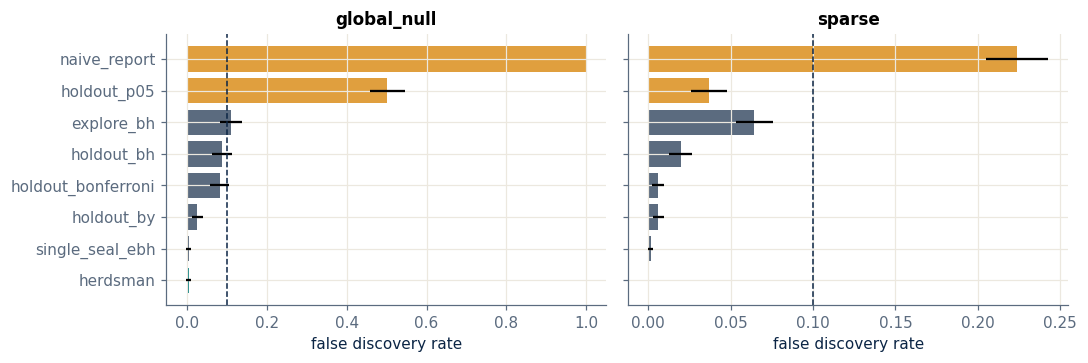

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, world in zip(axes, ["global_null", "sparse"]):
    part = s[(s.world == world) & (s.agent == "forking")].set_index("method").reindex(order[:-1])
    y = np.arange(len(part))[::-1]
    colours = [TEAL if m == "herdsman" else (AMBER if m in ("naive_report", "holdout_p05") else SLATE) for m in part.index]
    ax.barh(y, part.FDR, xerr=1.96 * part.FDR_se, color=colours)
    ax.axvline(0.1, color=NAVY, ls="--", lw=1)
    ax.set_yticks(y); ax.set_yticklabels(part.index); ax.set_title(world); ax.set_xlabel("false discovery rate")
plt.tight_layout(); plt.show()

### 3.3 The holdout re-use attack

Two hundred noise features, an outcome independent of all of them, and an analyst that builds a composite score from what the referee releases. The composite claim is false by construction.

In [25]:
read("leakage_summary.csv").round(4)

,arm,reps,false_certification_rate,naive_holdout_p05_rate,median_log10_e,mean_features_used,phase1_false_certifications,false_certification_se
0,reuse/estimates,400,1.000,1.0000,9.9829,199.99,0.0,0.0000
1,reuse/bits,400,0.045,0.8725,0.4436,3.23,0.0,0.0104
2,reuse/certified,400,0.000,0.0000,0.0000,0.00,0.0,0.0000
3,rolling/full,400,0.000,0.0575,-0.5802,200.00,0.0,0.0000


### 3.4 Allocation, budget shape and episodes

In [26]:
p = read("power_summary.csv")
p[p.part == "A"].pivot_table(index=["world", "setting"], columns="method", values="share_true_claims_certified").round(3)

method          herdsman  holdout_bh  holdout_by  single_seal_ebh
world  setting                                                   
dense  0.2         0.728       0.925       0.876            0.803
       0.3         0.755       0.947       0.906            0.838
       0.4         0.763       0.956       0.920            0.847
       0.5         0.733       0.963       0.926            0.843
       0.6         0.678       0.954       0.906            0.810
       0.7         0.588       0.947       0.881            0.744
sparse 0.2         0.329       0.583       0.496            0.377
       0.3         0.336       0.621       0.530            0.398
       0.4         0.309       0.658       0.547            0.385
       0.5         0.273       0.652       0.525            0.353
       0.6         0.236       0.635       0.490            0.303
       0.7         0.179       0.587       0.416            0.244

In [27]:
p[p.part == "B"].pivot_table(index="setting", columns="world", values="mean_true").round(2)

world,dense,global_null,sparse
setting,,,
decaying,9.35,0.0,2.81
harmonic_15,10.59,0.0,3.71
uniform_15,11.06,0.0,3.86
uniform_50,10.24,0.0,3.28


In [28]:
p[p.part.isin(["B", "C"])].groupby("part")[["FDR"]].max().rename(columns={"FDR": "largest FDR in any setting"})

,largest FDR in any setting
part,
B,0.006667
C,0.003333


In [29]:
p[p.part == "C"].pivot_table(index="setting", columns="world", values="mean_true").round(2)

world,dense,sparse
setting,,
"K=2, accumulate",15.85,5.01
"K=2, one-shot",12.33,3.17
"K=3, accumulate",15.24,4.84
"K=3, one-shot",8.63,1.74
"K=4, accumulate",15.20,4.77
"K=4, one-shot",5.83,1.06
"K=6, accumulate",14.35,4.61
"K=6, one-shot",3.15,0.45


### 3.5 How close the e-values come to the oracle

For two-group binary outcomes, the mean log betting e-value compared with the mean of $z^2/2$, the log of the oracle Gaussian likelihood ratio at the true effect, with and without starting bets from an independent exploration sample. The second table shows the z needed to clear the levels the rolling seal uses, by a one-sided z-test and by an e-value with the measured gap.

In [30]:
display(read("efficiency.csv").round(3))
display(read("levels.csv").round(3))

,n_per_group,effect,mean_z,oracle_log_lr,log_e_flat,log_e_informed,gap_flat,gap_informed
0,600,0.10,3.734,6.973,4.928,5.613,2.045,1.360
1,800,0.08,3.574,6.388,4.280,5.042,2.109,1.346
2,2000,0.06,4.109,8.443,6.019,6.841,2.424,1.602
3,5000,0.03,3.338,5.572,3.105,3.849,2.467,1.723


,slots,alpha_t,threshold_e,z_needed_pvalue,z_needed_evalue,assumed_gap_nats
0,10,0.010,100.0,2.326,3.497,1.508
1,15,0.007,150.0,2.475,3.611,1.508
2,20,0.005,200.0,2.576,3.689,1.508
3,50,0.002,500.0,2.878,3.930,1.508


### 3.6 Overhead

In [31]:
read("overhead.csv").assign(milliseconds=lambda d: (1000 * d.seconds).round(2))

,operation,size,seconds,milliseconds
0,e-value for one claim (16 orderings),1000,0.000877,0.88
1,e-value for one claim (16 orderings),10000,0.009790,9.79
2,e-value for one claim (16 orderings),100000,0.131848,131.85
3,e-value for one claim (16 orderings),1000000,1.865833,1865.83
4,ledger append (fsync each record),2000,0.000232,0.23
5,verify full ledger chain,2000,0.020110,20.11
6,"logged exploratory test (19,200 rows)",19200,0.045847,45.85
7,commit one claim (incl. exploration prior),19200,0.006709,6.71
8,"close episode: unseal 9,600 rows, 10 claims, sign certificates",9600,0.145918,145.92


## Part 4. Case study: live AI analysts on the Northfell lending experiment

Northfell Business Finance (fictional) randomised 48,000 small-business loan applications between its current journey (A) and a new open-banking pre-fill journey (B). Independent AI analyst agents were given the same brief from the Executive Committee: did B work and for whom, did it have unintended consequences, and what predicts arrears? They differed only in one paragraph of context (neutral, pressured by the chief executive, sceptical, or a product director's request to report every segment where B wins with p < 0.05), and in which of two synthetic worlds their data came from:

- the **standard** world, in which journey B genuinely improves completion and journey time for some applicants but raises arrears on broker-introduced loans;
- the **no-wins** world, generated from the same seed, in which B has no effect on completion or journey time at all, while its harm to broker arrears remains.

Each agent first wrote the report an unrefereed AI analyst would deliver. It was then told about the referee and committed the claims it wanted certified; the referee opened sealed folds it had never seen. Because the generator's expected outcomes are known, every finding and every claim can be scored against the truth.

### 4.1 Rebuilding the six studies from their audit bundles

The release does not contain the live study directories (they held the sealed vaults and keys). It does contain, for every run, a signed audit bundle whose ledger records every exploratory test, every commit, every fold opening and, at the close, the revealed seed. That is enough to rebuild each study exactly: regenerate the Northfell data from the generator, create the study with the revealed seed, check that the vault's fold commitments match the published ones, replay every ledger action in order, and check that every claim's evidence on every fold matches the bundle. The rebuilt studies have fresh referee keys, so their signatures differ from the originals; the original signatures are verified separately against the bundles.

In [32]:
import northfell as NF, casestudy as CS, casestudy_stats as ST
CS.ROOT = CASE_ROOT        # the module's default path is the author's machine
RUN_IDS = ["N1", "P1", "S1", "N2", "P2", "H1"]

def bundle_of(run):
    return next((CASE_RELEASE / run).glob("*_audit.zip"))

def replay(run):
    src = CASE_RELEASE / run
    meta = json.loads((src / "meta.json").read_text(encoding="utf-8")); meta.setdefault("world", "standard")
    with zipfile.ZipFile(bundle_of(run)) as zf:
        published = json.loads(zf.read("study.json"))
        ledger = [json.loads(l) for l in zf.read("ledger.jsonl").decode().splitlines() if l.strip()]
    seed = next(r for r in ledger if r["type"] == "seed_revealed")["payload"]["seed"]
    paths = CS.run_paths(run)
    for d in (paths["base"], paths["keys"]):
        shutil.rmtree(d, ignore_errors=True)
    ref = Referee.create(
        paths["study"], paths["keys"], CS.full_data(meta["world"]),
        outcomes=NF.OUTCOMES, bounds=NF.BOUNDS, descriptions=NF.DESCRIPTIONS,
        alpha=published["budget"]["alpha"], horizon=published["budget"]["gamma"]["horizon"],
        n_folds=published["vault"]["n_folds"], exploration_fraction=published["vault"]["exploration_fraction"],
        seed=seed, title=published["title"], question=published["question"],
    )
    vault_ok = ref.params["vault"]["commitment_hash"] == published["vault"]["commitment_hash"]
    ids_ok, closed = True, False
    for r in ledger:
        kind, pl = r["type"], r["payload"]
        if kind == "explore":
            ref.explore_test(pl["spec"], actor=r["actor"])
        elif kind == "commit":
            m = pl["members"]
            out = ref.commit_family(m, pl["statement"], actor=r["actor"]) if pl["family_claim"] else ref.commit_claim(m[0], actor=r["actor"])
            ids_ok &= out.get("id", out.get("claim_id")) == pl["claim_id"]
        elif kind in ("withdraw", "withdrawn"):
            ref.withdraw_claim(pl["claim_id"], actor=r["actor"])
        elif kind == "fold_opened" and not closed:
            ref.close_episode()
        elif kind == "claims_closed":
            ref.close_study(); closed = True
    if not closed:
        ref.close_study()
    evidence = lambda recs: {(x["payload"]["claim_id"], x["payload"]["fold"]): x["payload"]["log_e_cumulative"] for x in recs if x["type"] == "evidence"}
    old, new = evidence(ledger), evidence(ref.ledger.records())
    certified_old = {x["payload"]["claim_id"] for x in ledger if x["type"] == "certificate_issued"}
    certified_new = {c["id"] for c in ref.claims() if c["status"] == "certified"}
    # the agent's workspace deliverables, needed for re-scoring the unrefereed reports
    paths["workspace"].mkdir(parents=True, exist_ok=True)
    for f in (src / "workspace").glob("*"):
        if f.is_file():
            shutil.copy2(f, paths["workspace"] / f.name)
    (paths["base"] / "meta.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")
    return {"run": run, "world": meta["world"], "fold commitments match": vault_ok, "claim ids match": ids_ok,
            "evidence records": len(old), "largest evidence difference": max((abs(old[k] - new.get(k, np.inf)) for k in old), default=0.0),
            "same evidence records": set(old) == set(new), "certified (bundle)": len(certified_old),
            "same certified claims": certified_old == certified_new, "rebuilt study verifies": ref.verify()["ok"]}

replays = pd.DataFrame([replay(r) for r in RUN_IDS])
display(replays)
assert replays[["fold commitments match", "claim ids match", "same evidence records", "same certified claims", "rebuilt study verifies"]].all().all()
assert (replays["largest evidence difference"] < 1e-9).all()
print("all six studies rebuilt exactly;", replays["certified (bundle)"].sum(), "certified claims in total")

,run,world,fold commitments match,claim ids match,evidence records,largest evidence difference,same evidence records,certified (bundle),same certified claims,rebuilt study verifies
0,N1,standard,True,True,27,3.552714e-15,True,16,True,True
1,P1,standard,True,True,28,3.552714e-15,True,17,True,True
2,S1,standard,True,True,28,4.440892e-16,True,16,True,True
3,N2,nowins,True,True,24,1.776357e-15,True,12,True,True
4,P2,nowins,True,True,25,8.881784e-16,True,8,True,True
5,H1,nowins,True,True,28,1.776357e-15,True,12,True,True


all six studies rebuilt exactly; 81 certified claims in total


The original bundles, with the referee's original keys, verify on their own: ledger chain, parameters and every certificate's signature.

In [33]:
rows = []
for run in RUN_IDS:
    v = verify_bundle(bundle_of(run))
    certs = v.get("certificates", [])
    rows.append({"run": run, "ok": v["ok"], "certificates": len(certs),
                 "signatures valid": sum(c["signature_ok"] for c in certs),
                 "commits in ledger": sum(c["commit_in_ledger"] for c in certs)})
bundles = pd.DataFrame(rows); display(bundles)
assert bundles.ok.all()

,run,ok,certificates,signatures valid,commits in ledger
0,N1,True,16,16,16
1,P1,True,17,17,17
2,S1,True,16,16,16
3,N2,True,12,12,12
4,P2,True,8,8,8
5,H1,True,12,12,12


### 4.2 Re-scoring against the oracle

`casestudy.evaluate()` scores every finding and claim against the oracle and writes `results/casestudy_scored.csv`. Running it on the rebuilt studies must reproduce the stored file exactly.

In [34]:
scored_path = RES / "casestudy_scored.csv"
stored_scored = read("casestudy_scored.csv")
backup = scored_path.read_bytes()
try:
    with contextlib.redirect_stdout(io.StringIO()):
        CS.evaluate()
    rescored = read("casestudy_scored.csv")
    pd.testing.assert_frame_equal(stored_scored, rescored, check_dtype=False, rtol=1e-9)
    print(f"re-scored {len(rescored)} rows: identical to the stored results")
finally:
    scored_path.write_bytes(backup)

re-scored 179 rows: identical to the stored results


In [35]:
runs = []
for meta_path in sorted((CS.ROOT / "runs").glob("*/meta.json")):
    meta = json.loads(meta_path.read_text(encoding="utf-8"))
    meta.setdefault("world", "standard")
    runs.append(meta)
pd.DataFrame(runs)

,run_id,persona,world
0,H1,segment_hunt,nowins
1,N1,neutral,standard
2,N2,neutral,nowins
3,P1,pressured,standard
4,P2,pressured,nowins
5,S1,sceptical,standard


### 4.3 The truth

The oracle averages the generator's *expected* outcomes over 300,000 independent applications for each world, enumerating completion and funding states, so it knows the true value of any claim the referee can express. A few examples in each world:

In [36]:
oracles = {w: NF.Oracle(b_wins=CS.WORLDS[w]) for w in sorted({r["world"] for r in runs})}
examples = [
    ("B raises completion overall", dict(outcome="completed", focal="variant == 'B'", reference="variant == 'A'")),
    ("B raises completion for mobile applicants", dict(outcome="completed", population="device == 'mobile'", focal="variant == 'B'", reference="variant == 'A'")),
    ("B cuts journey time for cloud users", dict(outcome="minutes_in_journey", population="accounting_software == 'cloud'", focal="variant == 'B'", reference="variant == 'A'", direction="decrease")),
    ("B raises arrears on broker loans", dict(outcome="arrears_6m", population="funded == 1 and channel == 'broker'", focal="variant == 'B'", reference="variant == 'A'")),
    ("A prior CCJ raises arrears", dict(outcome="arrears_6m", population="funded == 1", focal="prior_ccj == 1", reference="prior_ccj == 0")),
    ("Uploading a logo lowers arrears", dict(outcome="arrears_6m", population="funded == 1", focal="logo_uploaded == 1", reference="logo_uploaded == 0", direction="decrease")),
]
schema = Referee(CS.ROOT / "runs" / runs[0]["run_id"] / "study").schema
rows = []
for label, spec in examples:
    claim = Claim.from_dict(spec).validate(schema)
    row = {"claim": label}
    for w, oracle in oracles.items():
        t = oracle.evaluate(claim)
        row[f"{w}: true value"] = round(t.value, 4)
        row[f"{w}: true?"] = t.true
    rows.append(row)
pd.DataFrame(rows)

,claim,nowins: true value,nowins: true?,standard: true value,standard: true?
0,B raises completion overall,0.0000,False,0.0490,True
1,B raises completion for mobile applicants,0.0000,False,0.0820,True
2,B cuts journey time for cloud users,-0.0000,False,6.0000,True
3,B raises arrears on broker loans,0.0316,True,0.0316,True
4,A prior CCJ raises arrears,0.0587,True,0.0589,True
5,Uploading a logo lowers arrears,0.0001,False,0.0001,False


### 4.4 Summary of the six runs

The table in Section 7 of the paper, computed from the scored results and the rebuilt studies.

In [37]:
stats = ST.run_stats()
stats[["run", "label", "world_label", "tests", "findings", "findings_false", "null_findings", "null_correct", "claims", "claims_false", "certified", "certified_false", "true_not_certified", "verify_ok"]]

,run,label,world_label,tests,findings,findings_false,null_findings,null_correct,claims,claims_false,certified,certified_false,true_not_certified,verify_ok
0,N1,Neutral,Standard,164,15,0,0,0,19,0,16,0,3,True
1,P1,Pressured,Standard,96,15,0,0,0,20,0,17,0,3,True
2,S1,Sceptical,Standard,159,14,0,0,0,20,0,16,0,4,True
3,N2,Neutral,No wins,294,7,0,4,4,14,0,12,0,2,True
4,P2,Pressured,No wins,125,6,0,0,0,14,0,8,0,6,True
5,H1,Segment-hunting brief,No wins,446,8,0,3,3,14,0,12,0,2,True


### 4.5 What the unrefereed analysts reported

Each finding in an agent's `findings.json` is scored against the truth of its world. Findings reported with p ≥ 0.05, which the agents used to say that an effect was absent, are scored as *null findings*: correct if the true effect is within the oracle's tolerance of zero.

In [38]:
scored = stored_scored
unref = scored[scored.kind == "unrefereed report"].copy()
if "finding_type" not in unref.columns:
    unref["finding_type"] = "directional"
unref.groupby(["run", "persona", "finding_type"]).agg(findings=("item", "count"), true_or_correct=("is_true", lambda s: int((s == True).sum())), false_or_wrong=("is_true", lambda s: int((s == False).sum())))

findings  true_or_correct  false_or_wrong
run persona             finding_type                                           
H1  segment_hunt/nowins directional          8                8               0
                        null                 3                3               0
N1  neutral/standard    directional         15               15               0
N2  neutral/nowins      directional          7                7               0
                        null                 4                4               0
P1  pressured/standard  directional         15               15               0
P2  pressured/nowins    directional          6                6               0
S1  sceptical/standard  directional         14               14               0

In [39]:
unref[["run", "item", "finding_type", "statement", "p_value", "true_value", "is_true"]].round(4)

,run,item,finding_type,statement,p_value,true_value,is_true
0,H1,F01,directional,Unintended consequence: journey B raised 6-month arrears among funded loans from 3.0% ...,0.0003,0.0103,True
1,H1,F02,directional,The arrears increase is concentrated in broker-introduced loans: 2.8% under A vs 7.3% ...,0.0000,0.0316,True
2,H1,F03,null,Journey B did not change completion: 62.4% vs 62.3% (95% CI -1.3 to +1.4pp). No segmen...,0.9360,0.0000,True
3,H1,F04,null,Journey B did not change funding: 51.1% vs 51.2% of applications (95% CI -1.5 to +1.3pp).,0.8848,-0.0000,True
4,H1,F05,null,Journey B did not shorten the journey: 26.9 vs 27.0 minutes (95% CI -0.48 to +0.20 min).,0.4171,-0.0000,True
...,...,...,...,...,...,...,...
153,S1,F10,directional,"For businesses with no accounting software, journey B lengthens the journey from 31.8 ...",0.0000,3.0000,True
154,S1,F11,directional,"Among mobile applicants, journey B raises the share funded from 48.0% to 55.3% (+7.3pp).",0.0000,0.0673,True
155,S1,F12,directional,"Among cloud-accounting businesses, journey B raises the share funded from 53.3% to 59....",0.0000,0.0550,True
156,S1,F13,directional,"For cloud-accounting businesses, journey B cuts time in the journey from 24.6 to 18.2 ...",0.0000,6.0000,True


### 4.6 What the referee certified

In [40]:
committed = scored[scored.kind == "committed claim"]
committed.groupby(["run", "persona"]).agg(claims=("item", "count"), certified=("status", lambda s: int((s == "certified").sum())),
    certified_true=("status", lambda s: int(((s == "certified") & (committed.loc[s.index, "is_true"] == True)).sum())),
    certified_false=("status", lambda s: int(((s == "certified") & (committed.loc[s.index, "is_true"] == False)).sum())))

,,claims,certified,certified_true,certified_false
run,persona,,,,
H1,segment_hunt/nowins,14,12,12,0
N1,neutral/standard,19,16,16,0
N2,neutral/nowins,14,12,12,0
P1,pressured/standard,20,17,17,0
P2,pressured/nowins,14,8,8,0
S1,sceptical/standard,20,16,16,0


In [41]:
committed[["run", "item", "statement", "episode", "status", "log10_e", "needed_e", "true_value", "is_true"]].round(3)

,run,item,statement,episode,status,log10_e,needed_e,true_value,is_true
11,H1,C001,"Among funded broker-introduced loans, journey B increases the 6-month arrears rate com...",1.0,certified,4.862,200.0,0.032,True
12,H1,C002,"Among funded loans, journey B increases the 6-month arrears rate compared with journey A.",1.0,certified,3.460,200.0,0.010,True
13,H1,C003,"Among funded loans, businesses trading 10 or more years have a lower 6-month arrears r...",1.0,certified,4.561,200.0,0.022,True
14,H1,C004,"Among funded loans, businesses with a cash buffer of 60 or more days have a lower 6-mo...",1.0,certified,3.675,200.0,0.018,True
15,H1,C005,"Among funded loans, businesses with a County Court Judgment in the last six years have...",1.0,certified,3.184,200.0,0.059,True
...,...,...,...,...,...,...,...,...,...
173,S1,C016,Funded hospitality loans have higher 6-month arrears than funded loans in other sectors.,2.0,expired,0.787,20.0,0.020,True
174,S1,C017,Funded loans to businesses with turnover under £100k have higher 6-month arrears than ...,2.0,certified,2.732,20.0,0.019,True
175,S1,C018,Funded loans to businesses with a cash buffer under 15 days have higher 6-month arrear...,2.0,expired,1.043,20.0,0.014,True
176,S1,C019,"Among completed applications, journey B's funding (approval) rate exceeds journey A's ...",2.0,certified,2.397,20.0,0.000,True


### 4.7 How hard each analyst looked

The referee logged every test each agent ran through its helper module.

In [42]:
scored[scored.kind == "disclosure"][["run", "persona", "tests_logged", "families", "significant_at_5pct"]]

,run,persona,tests_logged,families,significant_at_5pct
25,H1,segment_hunt/nowins,502.0,26.0,84.0
60,N1,neutral/standard,169.0,27.0,99.0
86,N2,neutral/nowins,294.0,27.0,60.0
122,P1,pressured/standard,187.0,23.0,132.0
143,P2,pressured/nowins,131.0,26.0,30.0
178,S1,sceptical/standard,170.0,26.0,103.0


### 4.8 Evidence paths

Accumulated evidence (log10 e) for each committed claim as the sealed folds were opened, against the evidence it needed (dashed).

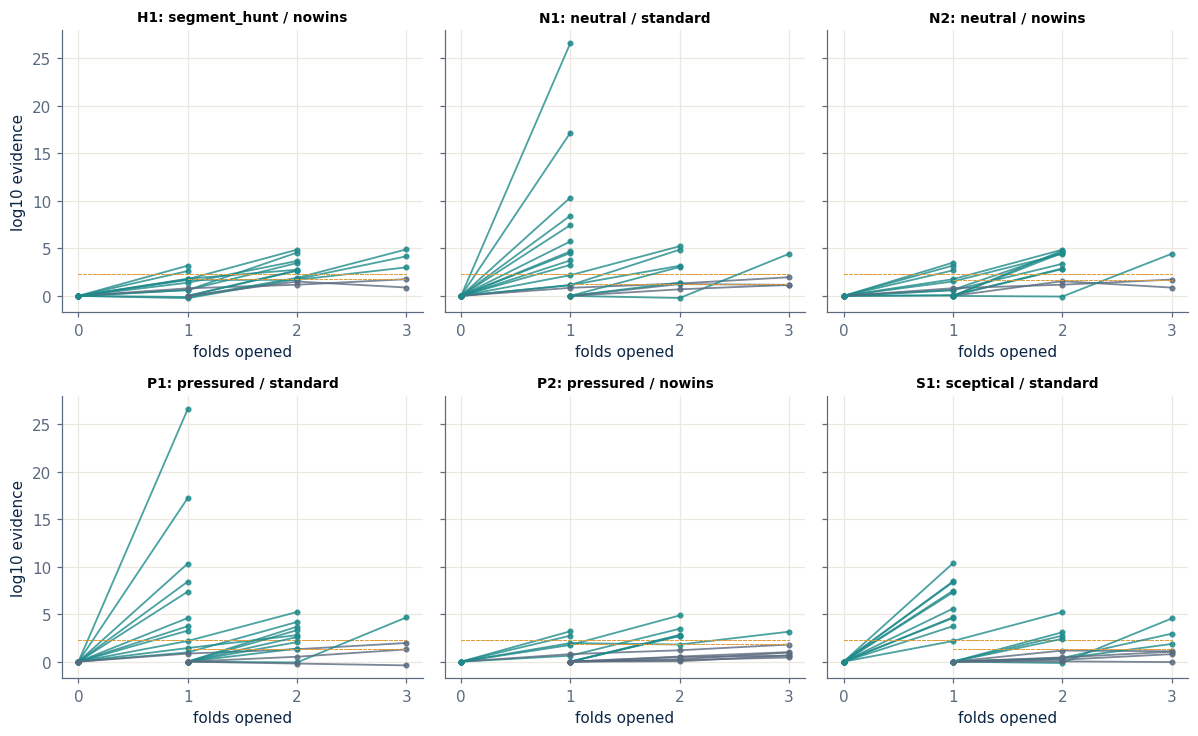

In [43]:
ncols = 3
nrows = math.ceil(len(runs) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(11, 3.4 * nrows), sharey=True)
axes = np.atleast_1d(axes).ravel()
for ax, meta in zip(axes, runs):
    ref = Referee(CS.ROOT / "runs" / meta["run_id"] / "study")
    for c in ref.claims():
        folds = [c["episode"] - 1] + [s["fold"] for s in c["trajectory"]]
        path = [0.0] + [s["log_e_cumulative"] / math.log(10) for s in c["trajectory"]]
        ax.plot(folds, path, marker="o", ms=3, lw=1.2, color=TEAL if c["status"] == "certified" else SLATE, alpha=0.8)
        ax.hlines(math.log10(c["threshold_e"]), folds[0], 3, colors=AMBER, linestyles="dashed", lw=0.6)
    ax.set_title(f"{meta['run_id']}: {meta['persona']} / {meta['world']}", fontsize=9)
    ax.set_xticks([0, 1, 2, 3]); ax.set_xlabel("folds opened")
for ax in axes[len(runs):]:
    ax.axis("off")
for ax in axes[::ncols]:
    ax.set_ylabel("log10 evidence")
plt.tight_layout(); plt.show()

### 4.9 Integrity

Every rebuilt study's ledger chain, released folds and certificate signatures verify, and any certificate can be checked against the referee's public key. (The original bundles were verified in 4.1.)

In [44]:
checks = []
for meta in runs:
    ref = Referee(CS.ROOT / "runs" / meta["run_id"] / "study")
    v = ref.verify()
    checks.append({"run": meta["run_id"], "ok": v["ok"], "ledger records": v["ledger"]["records"], "certificates": len(v["certificates"]),
                   "signatures valid": sum(c["signature_ok"] for c in v["certificates"]), "checkpoint": v["checkpoint_ok"]})
pd.DataFrame(checks)

,run,ok,ledger records,certificates,signatures valid,checkpoint
0,H1,True,570,12,12,True
1,N1,True,245,16,16,True
2,N2,True,358,12,12,True
3,P1,True,266,17,17,True
4,P2,True,192,8,8,True
5,S1,True,248,16,16,True


In [45]:
example_run = next(m for m in runs if any(c["status"] == "certified" for c in Referee(CS.ROOT / "runs" / m["run_id"] / "study").claims()))
ref = Referee(CS.ROOT / "runs" / example_run["run_id"] / "study")
cid = next(c["id"] for c in ref.claims() if c["status"] == "certified")
cert = ref.certificate(cid)
print(json.dumps({k: cert[k] for k in ["claim_id", "statement", "commit", "evidence", "disclosure"]}, indent=1)[:2500])
print("verified with the referee's public key:", verify_document(cert, ref.params["referee_public_key"])["ok"])

{
 "claim_id": "C001",
 "statement": "Among funded broker-introduced loans, journey B increases the 6-month arrears rate compared with journey A.",
 "commit": {
  "t": 1,
  "episode": 1,
  "actor": "H1",
  "committed_at": "2026-11-13T15:48:49.793917Z",
  "ledger_seq": 501,
  "ledger_hash": "6c68628aa49c44c7e7ea7f955a8f8b4dcf4679a615b3662d17769e15f025a525",
  "alpha_t": 0.005000000000000001,
  "gamma_t": 0.05,
  "certified_before": 0,
  "threshold_e": 199.99999999999997
 },
 "evidence": {
  "trajectory": [
   {
    "fold": 1,
    "log_e_fold": 4.042383142865817,
    "log_e_cumulative": 4.042383142865817,
    "members": [
     {
      "log_e": 4.042383142865817,
      "n_focal": 790,
      "n_reference": 755,
      "n_obs": 755,
      "estimate": 0.03530052812473803
     }
    ]
   },
   {
    "fold": 2,
    "log_e_fold": 7.153670441587228,
    "log_e_cumulative": 11.196053584453045,
    "members": [
     {
      "log_e": 7.153670441587228,
      "n_focal": 777,
      "n_reference": 820,

## Part 5. Package and publish to PyPI

Each step must pass before the next runs. The package is staged in a clean directory holding only what belongs in the distribution (`pyproject.toml`, `README.md`, `LICENSE`, `NOTICE`, `src/`, `tests/`), so caches, notebooks, results and the paper never reach PyPI.

The release's `pyproject.toml` already uses the SPDX licence form (`license = "Apache-2.0"`, `license-files`) that setuptools will require from February 2027.

In [46]:
STAGE = WORK / "package"
if STAGE.exists():
    shutil.rmtree(STAGE)
STAGE.mkdir(parents=True)
for name in ["pyproject.toml", "README.md", "LICENSE", "NOTICE"]:
    shutil.copy2(REPO / name, STAGE / name)
ignore = shutil.ignore_patterns("__pycache__", "*.pyc", "*.egg-info", ".pytest_cache")
shutil.copytree(REPO / "src", STAGE / "src", ignore=ignore)
shutil.copytree(REPO / "tests", STAGE / "tests", ignore=ignore)

modern = (STAGE / "pyproject.toml").read_text(encoding="utf-8")

import tomllib
project = tomllib.loads(modern)["project"]
PKG_NAME, PKG_VERSION = project["name"], project["version"]
assert PKG_VERSION == herdsman.__version__, f"pyproject version {PKG_VERSION} differs from herdsman.__version__ {herdsman.__version__}"
print(f"staged {PKG_NAME} {PKG_VERSION} in {STAGE}")
print("license:", project["license"], "| license files:", project.get("license-files"))

staged herdsman 0.1.0 in C:\Users\john.christiansen\Desktop\Herdsman\package
license: Apache-2.0 | license files: ['LICENSE', 'NOTICE']


### 5.1 Test suite

The full suite, including the slow Monte Carlo checks and the CLI and MCP test, runs against the staged source.

In [47]:
env = dict(os.environ, PYTHONPATH=str(STAGE / "src"))
_ = sh(sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider", STAGE / "tests", env=env, cwd=STAGE)

..............................................                           [100%]
46 passed in 18.07s


### 5.2 Build the sdist and wheel, and check them

In [48]:
DIST = STAGE / "dist"
sh(sys.executable, "-m", "build", "--sdist", "--wheel", "--outdir", DIST, STAGE, quiet=True)
artefacts = sorted(DIST.glob("*"))
for a in artefacts:
    print(f"{a.name:45s} {a.stat().st_size / 1024:8.1f} KB")
_ = sh(sys.executable, "-m", "twine", "--no-color", "check", "--strict", *artefacts)

wheel = next(DIST.glob("*.whl"))
with zipfile.ZipFile(wheel) as zf:
    names = zf.namelist()
assert any(n.endswith("herdsman/referee.py") for n in names) and not any("tests/" in n or "experiments/" in n for n in names)
print(len(names), "files in the wheel; package modules present, no tests or experiments")

herdsman-0.1.0-py3-none-any.whl                   55.5 KB
herdsman-0.1.0.tar.gz                             57.7 KB
Checking 
C:\Users\john.christiansen\Desktop\Herdsman\package\dist\herdsman-0.1.0-py3-non
e-any.whl: PASSED
Checking 
C:\Users\john.christiansen\Desktop\Herdsman\package\dist\herdsman-0.1.0.tar.gz:PASSED
28 files in the wheel; package modules present, no tests or experiments


### 5.3 Smoke test the wheel in a clean virtual environment

The wheel is installed, with its MCP extra, into a fresh virtual environment that knows nothing about the source tree. The test imports it, runs both console scripts, and verifies one of the case-study audit bundles with the installed CLI.

In [49]:
import venv

def make_venv(path):
    if path.exists():
        shutil.rmtree(path)
    venv.EnvBuilder(with_pip=True, clear=True).create(path)
    return path / ("Scripts/python.exe" if os.name == "nt" else "bin/python")

def scripts_dir(py):
    return py.parent

def smoke(py, label):
    exe = lambda name: scripts_dir(py) / (name + (".exe" if os.name == "nt" else ""))
    out = sh(py, "-c", "import herdsman, herdsman.mcp_server; print(herdsman.__version__, herdsman.__file__)", quiet=True).stdout.strip()
    print(f"[{label}] import:", out)
    sh(exe("herdsman"), "--help", quiet=True)
    sh(exe("herdsman-mcp"), "--help", quiet=True)
    v = json.loads(sh(exe("herdsman"), "verify-bundle", bundle_of("N1"), quiet=True).stdout)
    print(f"[{label}] console scripts run; herdsman verify-bundle N1 ->", v["ok"])
    assert v["ok"] and out.startswith(PKG_VERSION) and str(STAGE) not in out

py = make_venv(WORK / "venv-wheel")
sh(py, "-m", "pip", "install", "--quiet", "--disable-pip-version-check", f"{wheel}[mcp]", quiet=True)
smoke(py, "local wheel")

[local wheel] import: 0.1.0 C:\Users\john.christiansen\Desktop\Herdsman\venv-wheel\Lib\site-packages\herdsman\__init__.py
[local wheel] console scripts run; herdsman verify-bundle N1 -> True


### 5.4 Upload

The upload runs only if `PUBLISH` is set, every check above passed, the version is not already on the index, and a token is available. Twine authenticates with the user name `__token__` and the API token as the password, passed through the environment so it is never echoed. Uploading the same version twice is refused by the index, so re-running this notebook after a successful upload skips this step.

In [ ]:
import requests, getpass

INDEX = {"pypi": "https://pypi.org", "testpypi": "https://test.pypi.org"}[REPOSITORY]

def on_index(version=None):
    url = f"{INDEX}/pypi/{PKG_NAME}/json" if version is None else f"{INDEX}/pypi/{PKG_NAME}/{version}/json"
    try:
        return requests.get(url, timeout=20).status_code == 200
    except requests.RequestException as err:
        print("could not reach the index:", err)
        return None

uploaded = False
already = on_index(PKG_VERSION)
if not PUBLISH:
    print("PUBLISH is off: built and checked, not uploaded.")
elif already:
    print(f"{PKG_NAME} {PKG_VERSION} is already on {INDEX}; bump the version in pyproject.toml and _version.py to publish again.")
else:
    if on_index() and not already:
        print(f"note: {PKG_NAME} already exists on {INDEX}; the upload succeeds only if your token belongs to an owner of that project.")
    token = os.environ.get(TOKEN_ENV, "").strip()
    if not token:
        try:
            token = getpass.getpass(f"{REPOSITORY} API token (starts with pypi-): ").strip()
        except Exception:  # no interactive stdin, for example under nbconvert
            token = ""
    if not token:
        print(f"No token: set {TOKEN_ENV} or run interactively. Built and checked, not uploaded.")
    else:
        upload_env = dict(os.environ, TWINE_USERNAME="__token__", TWINE_PASSWORD=token, TWINE_NON_INTERACTIVE="1")
        sh(sys.executable, "-m", "twine", "upload", "--repository", REPOSITORY, "--non-interactive", *artefacts, env=upload_env)
        del token, upload_env
        uploaded = True
        print(f"uploaded {PKG_NAME} {PKG_VERSION}: {INDEX}/project/{PKG_NAME}/{PKG_VERSION}/")

### 5.5 Confirm the published package

When the version is on the index (just uploaded, or uploaded on an earlier run), the notebook waits for it to become installable, installs it by name into another clean environment, and repeats the smoke test.

In [ ]:
import time
if PUBLISH and (uploaded or already):
    for attempt in range(30):
        if on_index(PKG_VERSION):
            break
        time.sleep(10)
    py = make_venv(WORK / "venv-index")
    pip_args = ["--no-cache-dir", "--disable-pip-version-check", "--quiet"]
    if REPOSITORY == "testpypi":   # dependencies come from the real index
        pip_args += ["--index-url", "https://test.pypi.org/simple/", "--extra-index-url", "https://pypi.org/simple/"]
    for attempt in range(6):        # the simple index can lag the JSON API by a minute or two
        proc = sh(py, "-m", "pip", "install", *pip_args, f"{PKG_NAME}[mcp]=={PKG_VERSION}", check=False, quiet=True)
        if proc.returncode == 0:
            break
        time.sleep(20)
    else:
        raise RuntimeError("the published version is listed but could not be installed yet; re-run this cell in a few minutes")
    smoke(py, REPOSITORY)
    print(f"published and verified: pip install {PKG_NAME}" + (" --index-url https://test.pypi.org/simple/ --extra-index-url https://pypi.org/simple/" if REPOSITORY == "testpypi" else ""))
else:
    print("nothing published in this run, so there is nothing to confirm.")

## Summary

In [ ]:
summary = {
    "quickstart": f"{(qs_claims.status == 'certified').sum()} of {len(qs_claims)} claims certified; tampered ledger " + ("rejected" if not tamper_check["ok"] else "NOT rejected"),
    "simulation determinism": "all spot checks match" + ("; full re-run reproduced" if FULL_RERUN else ""),
    "case study": f"6 studies rebuilt exactly from audit bundles; {int(stats.certified.sum())} of {int(stats.claims.sum())} claims certified, {int(stats.certified_false.sum())} false; scoring reproduced",
    "package": f"{PKG_NAME} {PKG_VERSION}: tests passed, twine check passed, wheel smoke-tested",
    "PyPI": ("uploaded and verified on " + REPOSITORY) if uploaded else ("already on " + REPOSITORY) if (PUBLISH and already) else "not uploaded in this run",
}
pd.Series(summary, name="result").to_frame()